In [1]:
import sisl as si
from ase.visualize import view
from sisl.viz import *

In [2]:
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
from tqdm.notebook import tqdm
import time
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from matplotlib.colors import Normalize

In [3]:
si.__version__

'0.20.0'

In [4]:
from scipy.spatial import cKDTree

In [5]:
# Physical parameters

# Carbon Carbon bond distance
a_cc = 1.44
# Carbon Carbon hopping
t=2.7
# Carbon onsite
e0=0

# Reals Space Self Energies with `sisl`: a beginner's tutorial


So far, we have done transport calculations where semi-infinite electrodes were attached along a single transport direction (see *(b)*). 
A **real-space self-energy (RSSE)** provides a different type of embedding: it allows a finite region to reproduce the effect of an extended periodic environment around it (see *(c)*). This is particularly important when describing single defects on a material.

![title](./Figures/rsse.jpg)

A real-space self-energy is obtained from a Brillouin-zone-averaged Green function and embeds a finite device into an extended periodic 2D or 3D material. For an STM junction, this lets us model a local tip above an effectively infinite graphene sheet without periodically repeating the tip.

In TBtrans and TranSiesta one is capable of performing real-space transport calculations by using real-space self-energies (see here).
Currently, the real-space self-energy calculation has to be performed in sisl since it is not implemented in TranSiesta.



This tutorial introduces the basic ingredients of quantum transport calculations with **sisl** using real space (surrounding) self energies RSSE. 
The tutorial is divided into three parts:

1. **Real-space self-energies (RSSE) for graphene.** We build a simple graphene tight-binding model and use a real-space self-energy to embed a finite graphene region in an otherwise infinite graphene sheet. We then calculate the DOS and LDOS from the retarded Green function.
2. **Carbon vacancy in graphene**. We employ the real space self energy to study the localize state arising from a carbon vacancy in graphene.
3. **STM wire injecting into graphene.** We attach an explicit Au chain to the graphene device and calculate transmission and injected bond currents.
4. **Vertical graphene–CNT–graphene transport.** We construct a carbon nanotube (CNT) connected between two graphene sheets, reuse the graphene RSSEs as electrodes, and calculate transmission, DOS, and spatially resolved LDOS.

This tutorial was created by Alan Anaya mainly inspired by previous tutorials by Nick Papior

# I. Real-space self-energies for graphene

We introduce the method using pristine graphene and a simple nearest-neighbor $p_z$ tight-binding Hamiltonian. The finite region will later be reused as the graphene environment for the graphene–CNT–graphene device.

The RSSE is obtained from the Green function of the periodic reference system. Schematically,

$$\boldsymbol\Sigma^{\mathcal R}(E)=(E+i\eta)\mathbf S^{\mathcal R}-\mathbf H^{\mathcal R}-\left[\langle\mathbf G_{\mathbf k}(E)\rangle_{\mathrm{BZ}}\right]^{-1}.$$

The Brillouin-zone average carries the information of the infinite periodic graphene sheet into a finite real-space region. In practice, `sisl.RealSpaceSE` handles this construction for us.

The basic ingredient is the Brillouin-zone average of the periodic Green function:

$$\mathbf G^{\mathcal R}(E)=\langle\mathbf G_{\mathbf k}(E)\rangle_{\mathrm{BZ}}, \qquad \mathbf G_{\mathbf k}(E)=\left[(E+i\eta)\mathbf S_{\mathbf k}-\mathbf H_{\mathbf k}\right]^{-1}.$$

Here $\mathbf H_{\mathbf k}$ and $\mathbf S_{\mathbf k}$ are the Bloch Hamiltonian and overlap matrix. The average is normalized by the Brillouin-zone volume (or the $k$-point weights).

## 1. Graphene tight-binding Hamiltonian and band structure

We first construct a graphene unit cell and a nearest-neighbor $p_z$ tight-binding Hamiltonian. Each carbon atom has one orbital, with onsite energy `e0` and nearest-neighbor hopping `t`=-2.7 eV.

The band structure provides a quick check that the model has the expected graphene dispersion before it is used to construct the RSSE.

In [6]:
graphene = si.geom.graphene(a_cc)
graphene.set_nsc([3,3,1])

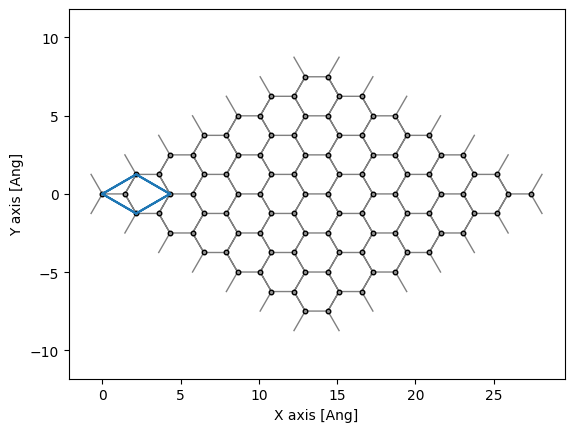

In [7]:
graphene.plot(axes='xy',nsc=(7,7,1),backend='matplotlib')

In [8]:
H_tb = si.Hamiltonian(graphene)
r = (0.1, a_cc+0.1)
t_v = (e0, t)
H_tb.construct([r,t_v])
H_tb.set_nsc([3,3,1])

In [9]:
band_pz = si.BandStructure(H_tb, [[0, 0, 0], [0, 0.5, 0],
                         [1/3, 2/3, 0], [0, 0, 0]], 400,
                        [r'$\Gamma$', r'$M$',
                         r'$K$', r'$\Gamma$'])

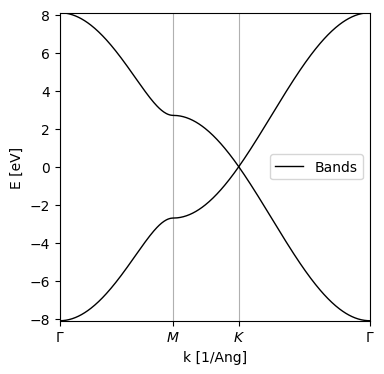

In [10]:
bands=band_pz.plot.bands(Erange=[-12,12], backend="matplotlib",)
fig = bands.get().figure
ax = bands.get().axes
fig.set_figwidth(4)
fig.set_figheight(4)

ax.legend()

## 2. Construct the real-space self-energy

We now create a `RealSpaceSE` object for an $N\times N$ graphene region. The periodic tight-binding Hamiltonian provides the reference environment, while the real-space size determines the finite region on which the embedding self-energy is represented.

The $k$-point sampling used in `setup` controls the Brillouin-zone average and should be converged for quantitative calculations.

The construction of this object is somewhat complicated and has a set of required input options:

1. `object`: the Hamiltonian
2. `semi_axis`: which axis to use for the recursive calculation of the self-energy
3. `k_axes`: which axes to integrate in the Brillouin zone
4. `unfold`: how many times the object needs to be unfolded along each lattice vector, this is an integer vector of length three

In [11]:
N=12
eta = 0.001
nk1 = int(np.ceil(3000/N))

# object = H_tb
# semi_axis = 0, x-axis uses recursive self-energy calculation
# k_axes = 1, y-axis uses a Brillouin zone integral
# unfold = (N, N, 1), the full real-space Green function is equivalent to the system

RSSE = si.RealSpaceSE(H_tb, 0, 1, (N, N, 1), eta = eta)  
RSSE.setup(bz=si.MonkhorstPack(H_tb, [1, nk1, 1]))

Now we can create the real-space self-energy.
In TBtrans (and TranSiesta) the electrode atomic indices must be in consecutive order. This is a little troublesome since the natural order in a device would be in order according to $x$, $y$ or $z$. To create the correct order we extract the real-space coupling matrix which is where the real-space self-energy would live. The self-energy $(\Sigma^{\mathcal R}(E)
)$ is calculated using:

$$\boldsymbol\Sigma^{\mathcal R}(E)=\mathbf S^{\mathcal R}(E)-\mathbf H^{\mathcal R}- (\boldsymbol G^{\mathcal R}(E))^{-1}$$
 
Where $\mathbf S^{\mathcal R}(E)$ and  $\mathbf H^{\mathcal R}$
are the real-space overlap matrix and Hamiltonian, respectively. Another way to calculate the self-energy would be to transfer the Green function from the infinite bulk $$ into the region of interest $\mathcal R$ :

$$\boldsymbol\Sigma^{\mathcal R}(E)=\mathbf V_{\infty/\mathcal R,\mathcal R}\mathbf G_{\mathcal R,\infty/\mathcal R}\mathbf V_{\mathcal R,\infty/\mathcal R}$$
The self-energy only lives on the boundary that $ \mathcal V_{\mathcal R,\infty/\mathcal R} $ couples to. Exactly this region is extracted using real_space_coupling as below. Take some time to draw a simple 2D lattice coupling and confirm the area that the real-space self-energies couple to. HINT: Draw the unit-cell for a 4x4 square lattice with nearest-neighbour couplings, then mark the atoms that couple to atoms outside the unit-cell.

`real_space_coupling(ret_indices=True)` returns the part of the real-space region that couples to the surrounding periodic environment, together with the corresponding atom indices. These are the atoms on which the coupling form of the RSSE acts.

In [12]:
H_rs_elec, rs_elec_indices = RSSE.real_space_coupling(ret_indices=True) ## The small one
H_rs_elec.set_nsc([3, 3,1])
nC = len(rs_elec_indices) 

Next we construct the finite $N	\times N$ graphene device. For convenience, we reorder its atoms so that the RSSE coupling atoms come **first**, followed by the atoms in the interior. This ordering is not a physical requirement; it simply makes the later matrix operations easier because the RSSE can be inserted directly into the upper-left block of the inverse Green-function matrix.

The `real_space_parent` method returns the Hamiltonian that obeys the unfolded size - in this case 
 times larger. One may always use this method to get the correct device order of atoms, since the order of tiling is determined by the semi_axes and k_axis arguments.

In [13]:
# Device Hamiltonian
# equivalent to H = rse.real_space_parent() 
#if we tile correctly with semiaxis and k_axis
HamNN=H_tb.tile(N,0).tile(N,1)
HamNN.set_nsc([1,1,1])
geomNN = HamNN.geometry

# Create the true device by re-arranging the atoms
# Get indices inside atoms and elec atoms
all_atoms=np.arange(0,HamNN.na)
inside_atoms = np.delete(all_atoms, rs_elec_indices)
Haminside=HamNN.sub(inside_atoms)
HamSE=HamNN.sub(rs_elec_indices)

# reorder indexes
alist = np.concatenate([rs_elec_indices, inside_atoms])
HamNN_reorder=HamNN.sub(alist)
HamNN_reorder.set_nsc([1,1,1])
HamNN_reorder.reduce()
#HamNN_reorder.write(HOME_DIR+'TBT/Device.nc')
na=HamNN_reorder.na

The following plot shows the reordered indexing. The electrode/coupling atoms appear first, while the remaining atoms form the interior of the finite graphene region. Checking this ordering visually is a useful way to avoid index-mapping errors later.

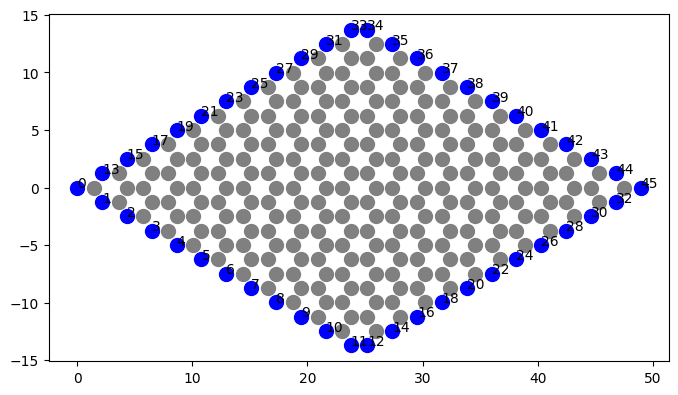

In [14]:
fig, ax = plt.subplots(figsize=(8,8))
ax.set_aspect('equal')
for i in np.arange(0,HamNN_reorder.na):
    if i < nC:
        ax.text(HamNN_reorder.xyz[i,0],HamNN_reorder.xyz[i,1],i,c='k')
        plt.scatter(HamNN_reorder.xyz[i,0],HamNN_reorder.geometry.xyz[i,1],c='b',s=100,label='Elec')
    else:
        plt.scatter(HamNN_reorder.xyz[i,0],HamNN_reorder.geometry.xyz[i,1],c='gray',s=100,label='Dev')

## 3. DOS and LDOS from the Green function

We now calculate the **density of states (DOS)** and **local density of states (LDOS)** from the retarded Green function of the embedded graphene region.For a non-orthogonal basis, the total DOS is evaluated as:

$$D(E)=-\frac{1}{\pi}\operatorname{Im}\,\mathrm{Tr}\left[\mathbf G^r(E)\mathbf S\right],$$ and the diagonal elements of $\mathbf G^r\mathbf S$ provide an orbital-resolved LDOS. Here each carbon atom has one orbital, so the orbital-resolved LDOS is also atom-resolved.

In [16]:
Hk= HamNN_reorder.Hk(format="array")   
Sk= HamNN_reorder.Sk(format="array")

`coupling=True` returns only the RSSE block acting on the coupling atoms identified above. Because those atoms were reordered to the beginning of the device, this block can be subtracted directly from `A[:n_elec, :n_elec]`.


In [15]:
def calc_DOS(E,eta,rse,H_sub,S_sub,n_elec):
    z = E +  eta*1j
    A = z*S_sub - H_sub 
    # Get RSSE
    RSE = rse.self_energy(E, coupling=True)
    A[:n_elec, :n_elec] -= RSE
    # Get G
    G = np.linalg.inv(A)   
    dos = - (1.0 / np.pi) * np.imag(np.trace(G@S_sub)) 
    ldos = - (1.0 / np.pi) * np.imag(np.diag(G@S_sub))
    return dos, ldos

def loop_DOS(energies,eta,rse,H_sub,S_sub,n_elec):
    # Observables
    N = H_sub.shape[0]
    DOS = np.zeros_like(energies, dtype=float)
    LDOS = np.zeros((N, len(energies)), dtype=float)  

    # Loop
    for iE, E in enumerate(tqdm(energies, desc='DOS')):
        dos,ldos =calc_DOS(E,eta,rse,H_sub,S_sub,n_elec)
        DOS[iE] = dos
        LDOS[:,iE] = ldos
    return DOS, LDOS

In [16]:
Emin = -3
Emax =  3
dE   =  0.1
En   = np.arange(Emin, Emax+dE, dE)

In [19]:
t0 = time.perf_counter()
DOS, LDOS=loop_DOS(En,eta,RSSE,Hk,Sk,nC)
t1 = time.perf_counter()
print(f"Total runtime: {t1 - t0:.2f} seconds")
print(f"Time per energy: {(t1 - t0)/len(En):.4f} s")
LDOS_dev= LDOS[nC:,:]
DOS_dev = LDOS_dev.sum(axis=0) 

DOS:   0%|          | 0/61 [00:00<?, ?it/s]

Total runtime: 44.14 seconds
Time per energy: 0.7236 s


Finally, we plot the DOS of the interior region. Away from the artificial boundary, the RSSE should make the finite system reproduce the electronic structure of pristine graphene. This provides a useful validation of the embedding before we use the same RSSE in a more complicated device.

In [20]:
# Find the closest energy
E0 = 0.5  # Energy of interest
E_idx = np.argmin(np.abs(En - E0))

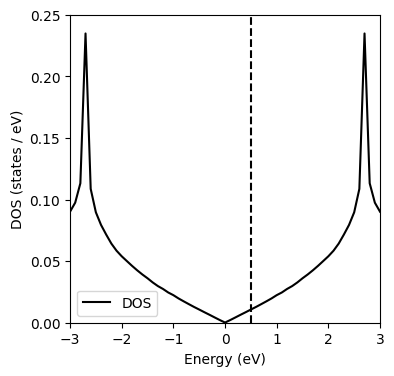

In [21]:
plt.figure(figsize=(4,4))
#plt.plot(tbt.E, tbt.DOS(), lw=1.5,c='r',label='TBT')
plt.plot(En,DOS_dev/na,c='k',label='DOS')
plt.xlabel("Energy (eV)")
plt.ylabel("DOS (states / eV)")
plt.vlines(x=En[E_idx],ymin=0,ymax=0.25,color='k',linestyle='dashed')
plt.xlim(-3,3)
plt.ylim(0,0.25)
plt.legend()
plt.show()

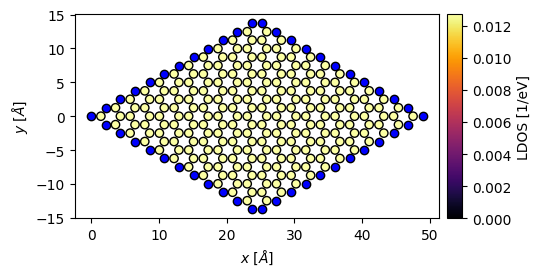

In [23]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_aspect("equal")

ax.scatter(HamNN_reorder.geometry.xyz[0:nC,:][:, 0], HamNN_reorder.geometry.xyz[0:nC,:][:, 1], 
              c='b',edgecolors='k')
sc=ax.scatter(HamNN_reorder.geometry.xyz[nC:,:][:, 0], HamNN_reorder.geometry.xyz[nC:,:][:, 1], 
              c=LDOS_dev.T[E_idx],cmap='inferno',vmin=0,edgecolors='k')

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%",  pad=0.08)
cbar = fig.colorbar( sc,   cax=cax)
cbar.set_label("LDOS [1/eV]")

ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$y$ [$\AA$]")
plt.show() 

### Visualizing the RSSE
We can plot where the self energy lives in the electrode region

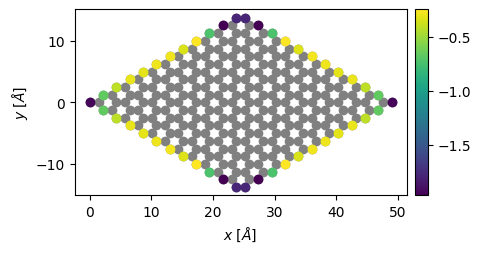

In [24]:
E = -0.5
eta  =   0.001
z = E +  eta
component="imag"

SE= RSSE.self_energy(E, coupling=True)

xyz = HamNN_reorder.geometry.xyz
x, y, z = xyz[:,0], xyz[:,1], xyz[:,2]
diag = np.real(SE.diagonal()) if component == "real" else np.imag(SE.diagonal())
vmin=min(diag)
vmax=max(diag)


fig, ax = plt.subplots(figsize=(5, 5))
ax.set_aspect('equal')
ax.scatter(x ,y,c='gray')

for i in np.arange(0,nC):
    sc=ax.scatter(x[i], y[i], c=diag[i],vmin=vmin,vmax=vmax,cmap='viridis')
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%",  pad=0.08)
cbar = fig.colorbar( sc,   cax=cax)
ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$y$ [$\AA$]")
plt.tight_layout()
plt.show()

# II. Single vacancy
Now we proceed to remove an atom in the device region. This atomic vacancy gives rise to a localize state

In [25]:
Ham_vac=HamNN_reorder.remove(178)

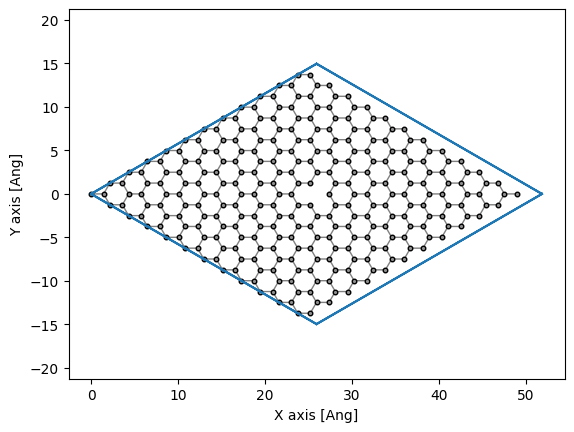

In [26]:
Ham_vac.geometry.plot(axes='xy',backend='matplotlib')

In [27]:
Hk= Ham_vac.Hk(format="array")   
Sk= Ham_vac.Sk(format="array")

In [ ]:
t0 = time.perf_counter()
DOS, LDOS=loop_DOS(En,eta,RSSE,Hk,Sk,nC)
t1 = time.perf_counter()
print(f"Total runtime: {t1 - t0:.2f} seconds")
print(f"Time per energy: {(t1 - t0)/len(En):.4f} s")
LDOS_vac= LDOS[nC:,:]
DOS_vac = LDOS_vac.sum(axis=0) 

In [42]:
# Find the closest energy
E0 = 1.2# Energy of interest
E_idx = np.argmin(np.abs(En - E0))

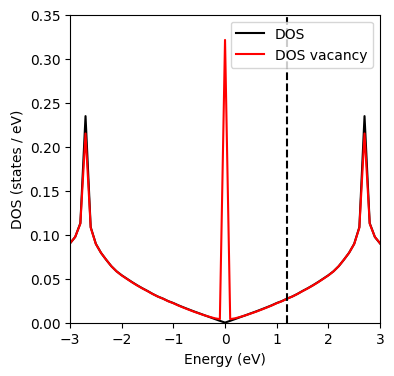

In [45]:
plt.figure(figsize=(4,4))
#plt.plot(tbt.E, tbt.DOS(), lw=1.5,c='r',label='TBT')
plt.plot(En,DOS_dev/na,c='k',label='DOS')
plt.plot(En,DOS_vac/(na-1),c='r',label='DOS vacancy')
plt.xlabel("Energy (eV)")
plt.ylabel("DOS (states / eV)")
plt.vlines(x=En[E_idx],ymin=0,ymax=0.5,color='k',linestyle='dashed')
plt.xlim(-3,3)
plt.ylim(0,0.35)
plt.legend()
plt.show()

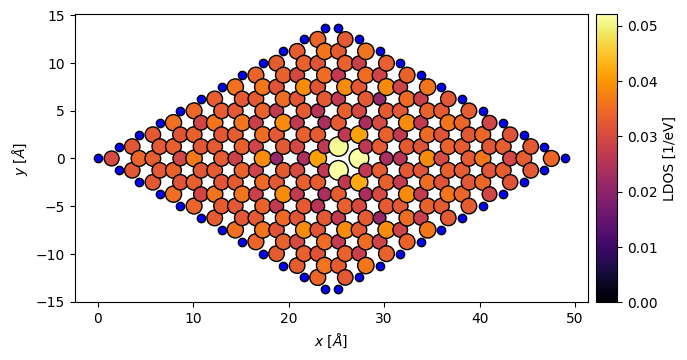

In [46]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.set_aspect("equal")

ax.scatter(HamNN_reorder.geometry.xyz[0:nC,:][:, 0], HamNN_reorder.geometry.xyz[0:nC,:][:, 1],  c='b',edgecolors='k')
sc=ax.scatter(Ham_vac.geometry.xyz[nC:,:][:, 0], Ham_vac.geometry.xyz[nC:,:][:, 1],  c=LDOS_vac.T[E_idx],s=200*LDOS_vac.T[E_idx]/np.max(LDOS_vac.T[E_idx]),cmap='inferno',vmin=0,edgecolors='k')

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%",  pad=0.08)
cbar = fig.colorbar( sc,   cax=cax)

cbar.set_label("LDOS [1/eV]")
ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$y$ [$\AA$]")
plt.show()

# III. Injection from a wire

We model an Au "STM" wire in contact with a carbon atom in pristine graphene. Five explicit Au atoms are included along $z$, and the semi-infinite continuation is represented by a recursive electrode self-energy.

### 1. Construct STM Hamiltonian

In [17]:
STM = si.Geometry([0, 0, 0], atoms=si.Atom('Au', R=1.0001), lattice=si.Lattice([10, 10, 1], nsc=[1, 1, 3]))
STM=STM.tile(5,2)
H_STM = si.Hamiltonian(STM)
H_STM.construct([(0.1, 1.1), (0, -0.75)])

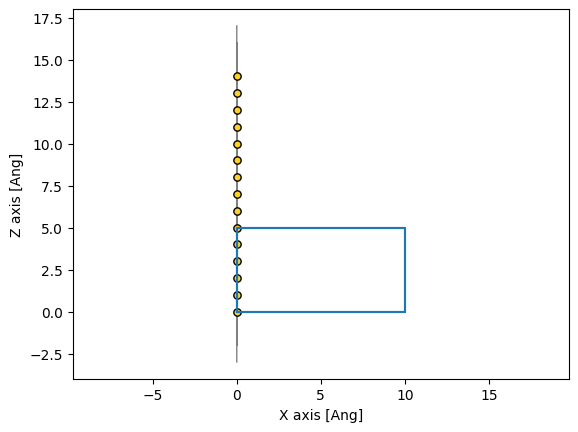

In [18]:
H_STM.geometry.plot(axes="xz",nsc=[1,1,3],backend='matplotlib')

We plot the band structure of the wire to show that it is a metallic system.

In [19]:
band_stm = si.BandStructure(H_STM, [[0, 0, 0.5], [0, 0,0],[0, 0, 0.5]],30,[r'$Z$', r'$\Gamma$',r'$Z$'])

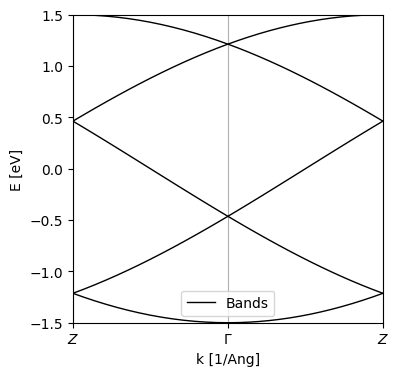

In [20]:
bands=band_stm.plot.bands(Erange=[-12,12], backend="matplotlib",)
fig = bands.get().figure
ax = bands.get().axes
fig.set_figwidth(4)
fig.set_figheight(4)
ax.legend()

### 2. Contact the STM to graphene

We contact the first Au atom of the wire with a carbon atom in graphene. The hopping is set explicitly in both directions to keep the device Hamiltonian Hermitian.

In [35]:
idx_atom= 178
H_gr_stm = HamNN_reorder.add(H_STM, offset=HamNN_reorder.geometry.xyz[idx_atom] - H_STM.geometry.xyz[0] + [0, 0, 2])

idx_au = H_gr_stm.na- H_STM.na
H_gr_stm[idx_atom, idx_au] = - 1
H_gr_stm[idx_au, idx_atom] = -1

# Remove periodic image hoppings from the finite device; the +C SE supplies the wire continuation.
H_gr_stm.set_nsc([1, 1, 1])

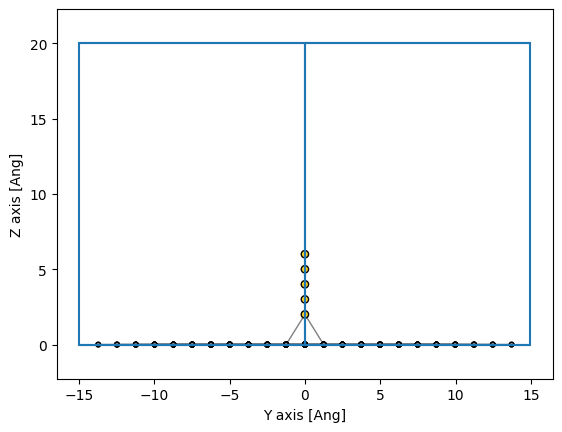

In [36]:
H_gr_stm.geometry.plot(axes="yz",backend='matplotlib')

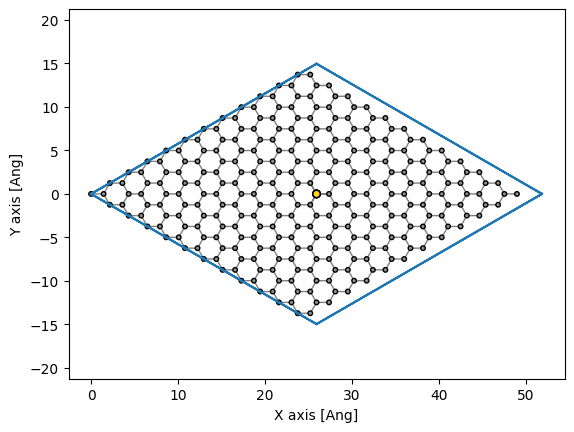

In [37]:
H_gr_stm.geometry.plot(axes="xy",backend='matplotlib')

### 3. Calculate the Transmission

The `+C` recursive self-energy represents the continuation of the wire beyond its last explicit Au atom. It acts on the wire block; the coupling to graphene is already included in the device Hamiltonian.

In [38]:
SE_STM = si.RecursiveSI(H_STM,   "+C",    eta=1e-5)

In [39]:
# embed electrodes on the first atoms of the rsse
n_elec = len(rs_elec_indices) 
rsse_idx= np.arange(n_elec)
# Self energy on stm atoms
STM_idx =np.arange(H_gr_stm.na-H_STM.na,H_gr_stm.na)

In [40]:
Hk= H_gr_stm.Hk(format="array")   
Sk= H_gr_stm.Sk(format="array")

In [41]:
dos_total  = np.zeros(len(En))
ldos       = np.zeros((len(En),H_gr_stm.na))  

We calculate the transmission from the Au wire to graphene  over a chosen energy range. For each energy we:

1. evaluate the bottom and top coupling self-energies, one with rsse electrode the second with semi-infinite electrode
2. insert them into the corresponding blocks of the full device matrix,
3. invert the open-system matrix to obtain $\mathbf G^r$,
4. construct the broadening matrices $\boldsymbol\Gamma_B$ and $\boldsymbol\Gamma_T$, and
5.  evaluate
$$T(E)=\mathrm{Tr}\left[\boldsymbol\Gamma_B\mathbf G^r\boldsymbol\Gamma_T\mathbf G^a\right].$$

The same Green function gives the DOS projected onto graphene and the five explicit Au atoms. (This example uses pristine graphene, not the vacancy Hamiltonian.)


In [42]:
transmission = np.zeros(len(En))
for iE, E in enumerate(tqdm(En, unit="E")):
    z = E + 1j * eta
    A = z * Sk - Hk

    # RSSE 
    RSE = RSSE.self_energy(E,coupling=True) 
    SE_B=np.zeros(A.shape,dtype=complex)
    SE_B[np.ix_(rsse_idx, rsse_idx)] -= RSE # note the minus 

    # STM SE
    Sigma_STM = SE_STM.self_energy( E)
    SE_T=np.zeros(A.shape,dtype=complex)
    SE_T[np.ix_(STM_idx, STM_idx)] -= Sigma_STM # note the minus 

    A+= (SE_B+SE_T)

    # Greens function 
    G = np.linalg.inv(A)

    # SE_B/SE_T store -Sigma; undo that minus sign when forming Gamma.
    Gamma_B = -1j * (SE_B - SE_B.conj().T)
    Gamma_T = -1j * (SE_T - SE_T.conj().T)

    # Transmission
    transmission[iE] = np.real(np.trace( Gamma_B @ G @ Gamma_T@ G.conj().T))
    GS = G @ Sk

    dos_atom = -np.imag( np.diag(GS) ) / np.pi
    dos_total[iE] = dos_atom.sum()
    ldos[iE] = - (1.0 / np.pi) * np.imag(np.diag(GS))

  0%|          | 0/61 [00:00<?, ?E/s]

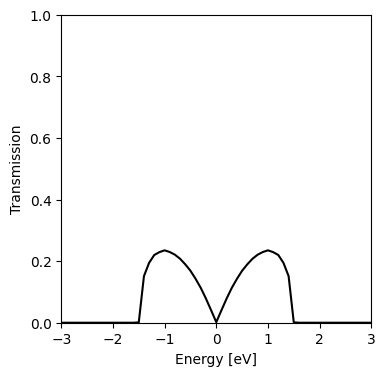

In [44]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(En,transmission,c='k')
ax.set_xlabel("Energy [eV]")
ax.set_ylabel("Transmission")
plt.xlim(-3,3)
plt.ylim(1e-12,1)
plt.yscale('log')
plt.show()

### 4. Plot the DOS

In [45]:
geom = H_gr_stm.geometry  # Hamiltonian
xyz=geom.xyz

graphene_atoms = np.array([ ia for ia, atom in enumerate(geom.atoms)if atom.Z == 6])
wire_atoms = np.array([ ia for ia, atom in enumerate(geom.atoms) if atom.Z == 79])
dos_graphene = ldos[:, graphene_atoms].sum(axis=1)
dos_wire = ldos[:, wire_atoms].sum(axis=1)
dos_atom = ldos[:, np.array([idx_atom])].sum(axis=1)

In [47]:
# Find the closest energy
E0 =0.3# Energy of interest
E_idx = np.argmin(np.abs(En - E0))

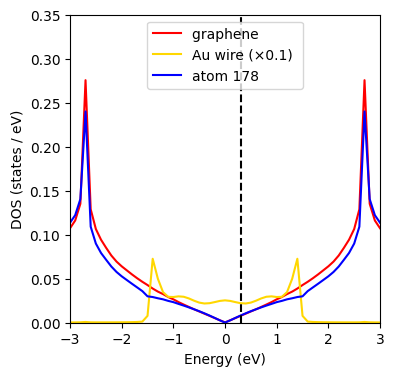

In [48]:
plt.figure(figsize=(4,4))
plt.plot(En,dos_graphene/len(graphene_atoms),c='r',label='graphene ')
plt.plot(En,0.1*dos_wire/len(wire_atoms),c='gold',label='Au wire (×0.1) ')
plt.plot(En,dos_atom,c='b',label=f'atom {idx_atom} ')
plt.xlabel("Energy (eV)")
plt.ylabel("DOS (states / eV)")
plt.vlines(x=En[E_idx],ymin=0,ymax=0.5,color='k',linestyle='dashed')
plt.xlim(-3,3)
plt.ylim(0,0.35)
plt.legend()
plt.show()

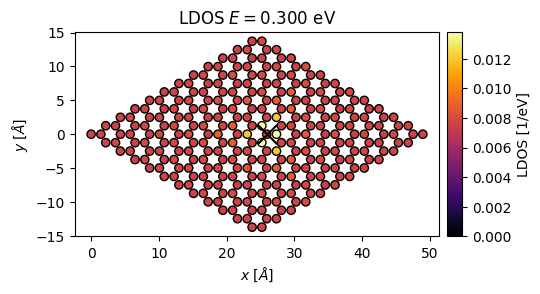

In [54]:
# values to plot the ldos
vmin = 0.0
vmax =np.max(ldos[:, graphene_atoms][E_idx])
vals = ldos[:][E_idx]


fig, ax = plt.subplots(figsize=(5,5))
ax.set_aspect("equal")

sc = ax.scatter( xyz[graphene_atoms, 0], xyz[graphene_atoms, 1], c=vals[graphene_atoms],  cmap="inferno",  vmin=vmin,  vmax=vmax,  edgecolors="k")
ax.scatter( xyz[idx_atom, 0], xyz[idx_atom, 1], c='k',  marker='x',s=200)

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.08)
cbar = fig.colorbar(sc, cax=cax)
cbar.set_label("LDOS [1/eV]")
ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$y$ [$\AA$]")
ax.set_title(rf"LDOS $E={En[E_idx]:.3f}$ eV")

plt.show()

### 5. STM-injected spectral bond currents

At a selected energy $E_0$, the **spectral weight** from the STM contact is

$$\mathbf A_T(E_0)=\mathbf G^r(E_0)\boldsymbol\Gamma_T(E_0)\mathbf G^a(E_0), \qquad \boldsymbol\Gamma_T=i(\boldsymbol\Sigma_T-\boldsymbol\Sigma_T^\dagger).$$

The energy-resolved particle flow from orbital $i$ to $j$ (positive for $i\to j$) is

$$j_{i\to j}^{(T)}(E_0)=-2\,\mathrm{Im}\!\left[\big(H_{ij}-E_0S_{ij}\big)(A_T)_{ji}\right].$$

Here each atom has one orthogonal orbital, so $S_{ij}=0$ for distinct atoms. **Only nonzero Hamiltonian bonds carry a bond current.** The arrow direction indicates the sign; its color indicates $|j|$. The result is an energy-resolved *STM-injected* contribution, not a finite-bias current by itself. A two-terminal charge current requires the occupation difference, with $I=(e/h)\int dE\,[f_T(E)-f_B(E)]\,T(E)$ per spin (up to the chosen sign convention).

In [64]:
# Find the closest energy
E0 =0.3# Energy of interest

In [65]:
# Use the explicitly selected energy, not E left over from the energy loop.
E = E0
z = E + 1j * eta
A = z * Sk - Hk

# RSSE
RSE = RSSE.self_energy(E, coupling=True)
SE_B = np.zeros(A.shape, dtype=complex)
SE_B[np.ix_(rsse_idx, rsse_idx)] -= RSE

# STM SE
Sigma_STM = SE_STM.self_energy(E)
SE_T = np.zeros(A.shape, dtype=complex)
SE_T[np.ix_(STM_idx, STM_idx)] -= Sigma_STM

A += (SE_B + SE_T)

# Green function
G = np.linalg.inv(A)

# SE_B and SE_T store -Sigma (rather than Sigma).
Gamma_B = -1j * (SE_B - SE_B.conj().T)
Gamma_T = -1j * (SE_T - SE_T.conj().T)

# STM-injected spectral function (G^r Gamma_T G^a)
A_T = G @ Gamma_T @ G.conj().T

In [66]:
xyz = H_gr_stm.geometry.xyz

# Candidate near-neighbor bonds; keep only actual Hamiltonian couplings.
tree = cKDTree(xyz)
bonds = np.array(sorted(tree.query_pairs(r=2.05)), dtype=int).reshape(-1, 2)
atom_i, atom_j = bonds[:, 0], bonds[:, 1]
coupled = np.abs(Hk[atom_i, atom_j] - E0 * Sk[atom_i, atom_j]) > 1e-12
atom_i, atom_j = atom_i[coupled], atom_j[coupled]

# Spectral particle flow i -> j, injected from the STM wire.
Jij = -2 * np.imag(
    (Hk[atom_i, atom_j] - E0 * Sk[atom_i, atom_j]) * A_T[atom_j, atom_i]
)

# Check the graphene--first-Au bond flux against the total transmission.
tip_bond = (atom_i == idx_atom) & (atom_j == idx_au)
if np.any(tip_bond):
    T_E0 = np.real(np.trace(Gamma_B @ G @ Gamma_T @ G.conj().T))
    print(f"Au -> graphene bond flux: {-Jij[tip_bond].sum():.5g}; T(E0): {T_E0:.5g}")

# A negative current is represented by reversing the arrow.
i, j, J = atom_i, atom_j, Jij
start = np.where(J[:, None] >= 0, xyz[i], xyz[j])
end = np.where(J[:, None] >= 0, xyz[j], xyz[i])
dx = end[:, 0] - start[:, 0]
dy = end[:, 1] - start[:, 1]
dz = end[:, 2] - start[:, 2]

Au -> graphene bond flux: 0.1141; T(E0): 0.11306


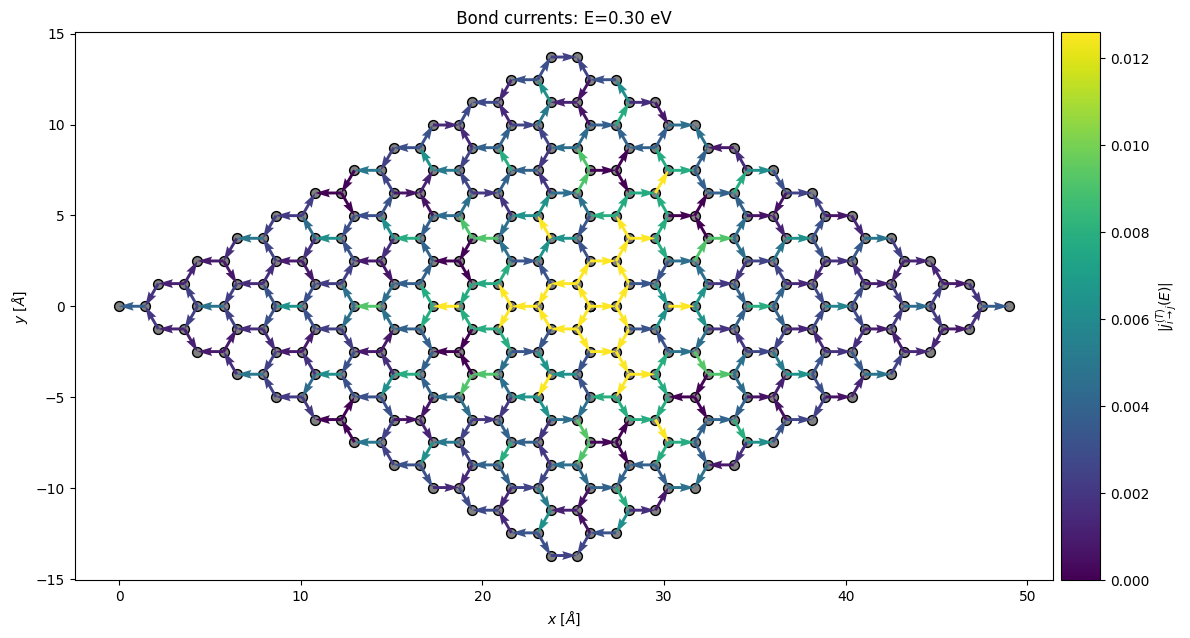

In [67]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_aspect("equal")

# Device atoms (carbon + Au)
ax.scatter(xyz[:, 0], xyz[:, 1],s=50, c="gray",zorder=0,edgecolors='k')

# Bond-current arrows
q = ax.quiver(
    start[:, 0],
    start[:, 1],
    dx,
    dy,
    np.abs(J),
    cmap="viridis",
    norm=Normalize(vmin=0, vmax=0.1*np.max(np.abs(Jij))  ),  # Clip strong bonds to reveal weaker currents.
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.003,
    headwidth=3,
    zorder=2
)

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.08)
cbar = fig.colorbar(q, cax=cax)
cbar.set_label(label=r"$|j_{i\to j}^{(T)}(E)|$")


ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$y$ [$\AA$]")

ax.set_title( rf" Bond currents: E={E0:.2f} eV ")

plt.tight_layout()
plt.show()


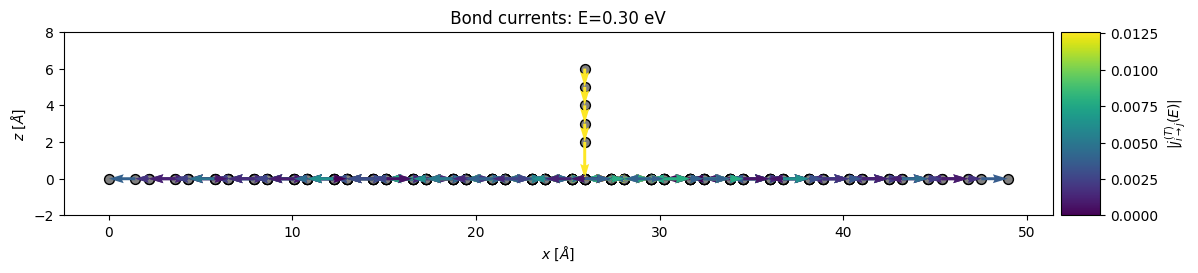

In [68]:
fig, ax = plt.subplots(figsize=(12, 12))
ax.set_aspect("equal")

# Device atoms (carbon + Au)
ax.scatter(xyz[:, 0], xyz[:,2],s=50, c="gray",zorder=0,edgecolors='k')

# Bond-current arrows
q = ax.quiver(start[:, 0], start[:, 2],  dx, dz, np.abs(J),
    cmap="viridis",
    norm=Normalize(vmin=0, vmax=0.1*np.max(np.abs(Jij))  ),  # Clip strong bonds to reveal weaker currents.
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.003,
    headwidth=3,
    zorder=2
)

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.08)
cbar = fig.colorbar(q, cax=cax)
cbar.set_label(label=r"$|j_{i\to j}^{(T)}(E)|$")



ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$z$ [$\AA$]")

ax.set_title( rf" Bond currents: E={E0:.2f} eV ")
ax.set_ylim(-2,8)
plt.tight_layout()
plt.show()

### 5. Exercise: Now study the STM contacted to a carbon close to a vacancy


# IV. Vertical transport through a carbon nanotube

## 1. CNT Band Strucutre


In [192]:
cnt=si.get_sile("CNT/cnt_prist.xyz").read_geometry()

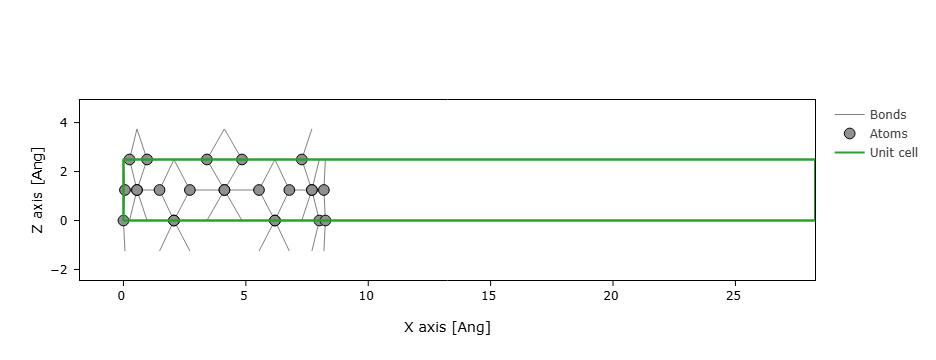

In [193]:
cnt.plot(axes='xz')

In [ ]:
H_tb = si.Hamiltonian(cnt)
r = (0.1, a_cc+0.1)
t_v = (e0, t)
H_tb.construct([r,t_v])

In [195]:
nk=50
band_tb = si.BandStructure(H_tb, [[0.0, 0, 0], [0, 0, 1/2]],nk, [r'$\Gamma$', r'$Z$'])
lk, kt, kl = band_tb.lineark(True)
bs_tb =band_tb.apply.array.eigh()

Text(0, 0.5, '$E-E_F$ (eV)')

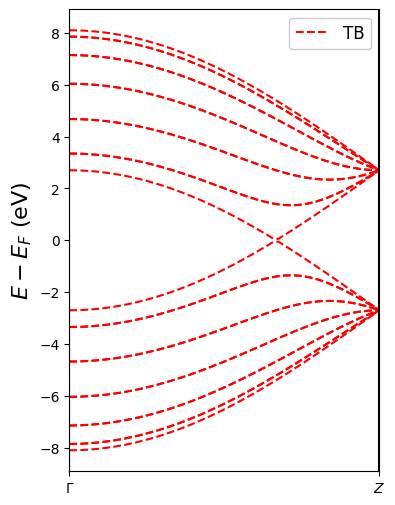

In [196]:
fig, ax = plt.subplots(figsize=(4, 6))

firsttime=True
for bk in bs_tb.T:
    bk=bk 
    if(firsttime):
        ax.plot(lk, bk, 'r--', label=r'TB')
        firsttime=False
    else:
        ax.plot(lk, bk, 'r--')


xcoords = kt
for k in xcoords:
    plt.axvline(x=k,c='k')        
plt.xticks(kt, kl)        
ax.legend(loc='upper right',fontsize=12,framealpha=1)
#plt.ylim(-1.5,1.5)
plt.xlim(kt[0],kt[1])
plt.ylabel(r'$E-E_F$ (eV)',fontsize=16)

We employ a Monkhorst-Pack grid to calculate the k-averaged DOS.

In [197]:
bz = si.MonkhorstPack(H_tb, [1, 1, 1000])
bz_average = (bz.apply.average);  

We use a gaussian distribution to smear the DOS

In [198]:
Energies = np.linspace(-3, 3, 1001)

sigma = 0.01
dist = si.get_distribution("gaussian", smearing=sigma)

DOS_CNT = bz_average.eigenstate(    wrap=lambda es: es.DOS(Energies, distribution=dist)) / H_tb.na

(0.0, 0.2882775723227)

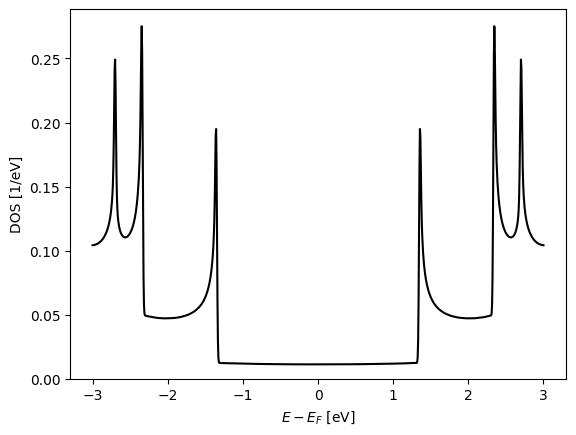

In [199]:
plt.plot(Energies,DOS_CNT,c='k' )
plt.xlabel("$E - E_F$ [eV]")
plt.ylabel("DOS [1/eV]");
plt.ylim(0,None)

## 2. Construct the device Hamiltonian

We now read the graphene–CNT–graphene structure written to the FDF file and construct its tight-binding Hamiltonian.

The atom ordering is important and was chosen deliberately as

**bottom graphene $\rightarrow$ CNT $\rightarrow$ top graphene**.

Within each graphene block, the RSSE coupling atoms remain first. This lets us reuse the coupling self-energy calculated in Section II without an additional coordinate remapping.
We have created carbon nanotubes of **6** and **12** repetitions for you.

In [271]:
n=6

In [272]:
gr_cnt_gr=si.get_sile(f"CNT/CNT{n}_device.fdf").read_geometry()

In [273]:
# this geometries are used to keep track of the atom indices
gr_bot=si.get_sile("CNT/gr_bot.xyz").read_geometry()
n_bottom=gr_bot.na

cnt=si.get_sile(f"CNT/cnt_{n}.xyz").read_geometry()
n_cnt=cnt.na

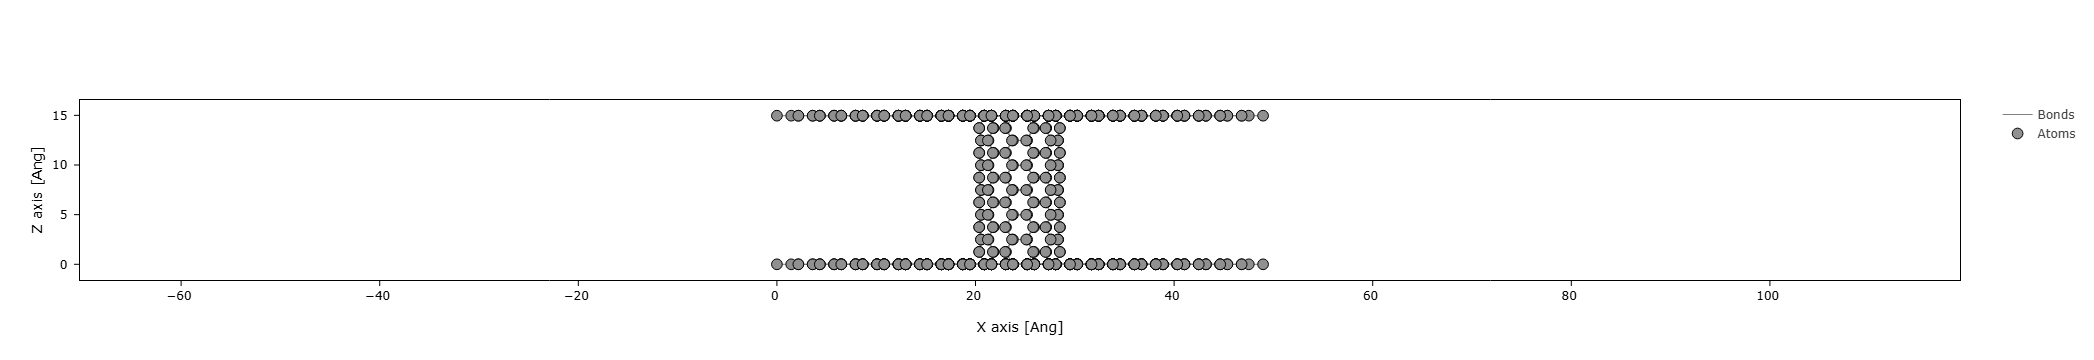

In [274]:
gr_cnt_gr.plot(axes="xz",show_cell=False)

In [275]:
H_dev = si.Hamiltonian(gr_cnt_gr)
r = (0.1, a_cc+0.1)
t_v = (e0, t)
H_dev.construct([r,t_v])

warn:0: SislWarning:

Geometry.close_sc has been passed an 'atoms' argument together with an R value larger than the orbital ranges. If used together with 'sparse-matrix.construct' this can result in wrong couplings.



## 3. Transport with RSSE for bottom and top graphene

The bottom and top electrodes are identical pristine graphene environments, so the same RSSE construction can be used for both sides. We keep separate variables (`RSSE_bottom` and `RSSE_top`) to make the two-electrode structure of the calculation explicit.

In [276]:
RSSE_bottom=RSSE
RSSE_top=RSSE
n_dev    = gr_cnt_gr.na
n_elec = len(rs_elec_indices) 

We calculate the transmission from the bottom graphene sheet to the top graphene sheet over a chosen energy range. For each energy we:

1. evaluate the bottom and top coupling self-energies,
2. insert them into the corresponding blocks of the full device matrix,
3. invert the open-system matrix to obtain $\mathbf G^r$,
4. construct the broadening matrices $\boldsymbol\Gamma_B$ and $\boldsymbol\Gamma_T$, and
5.  evaluate
$$T(E)=\mathrm{Tr}\left[\boldsymbol\Gamma_B\mathbf G^r\boldsymbol\Gamma_T\mathbf G^a\right].$$

The same Green function is also used to calculate the total DOS and its projections onto the bottom graphene, CNT, and top graphene regions.

In [277]:
Emin = -3
Emax =  3
dE   =  0.1
eta  =   0.001
En   = np.arange(Emin, Emax+dE, dE)

In [278]:
H_dev.set_nsc([1,1,1])

In [279]:
Hk= H_dev.Hk(format="array")   
Sk= H_dev.Sk(format="array")

Because the device ordering is **bottom graphene $\rightarrow$ CNT $\rightarrow$ top graphene**.
the global indices of the two RSSE coupling regions follow directly from the sizes of these three blocks.


In [280]:
# Bottom graphene starts at 0
rs_bottom_global = np.arange(n_elec)

# Top graphene starts after bottom + CNT
top_offset = n_bottom + n_cnt
rs_top_global = top_offset + np.arange(n_elec)

In [281]:
idx_electrodes = np.concatenate([rs_bottom_global, rs_top_global])

idx_dev= np.setdiff1d(np.arange(0,H_dev.na), idx_electrodes)

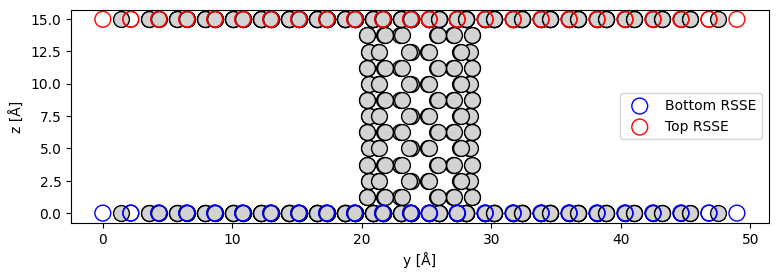

In [282]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.set_aspect("equal")

ax.scatter( gr_cnt_gr.xyz[rs_bottom_global,0], gr_cnt_gr.xyz[rs_bottom_global, 2], facecolors="none", edgecolors="blue", s=130, label="Bottom RSSE",zorder=2)
ax.scatter(  gr_cnt_gr.xyz[rs_top_global, 0],  gr_cnt_gr.xyz[rs_top_global, 2],  facecolors="none",   edgecolors="red",  s=130,   label="Top RSSE",zorder=2)
ax.scatter(  gr_cnt_gr.xyz[idx_dev,0],  gr_cnt_gr.xyz[idx_dev, 2],  c="lightgray",  edgecolors="k",  zorder=0,  s=130)

ax.legend()
ax.set_xlabel("y [Å]")
ax.set_ylabel("z [Å]")
plt.show()

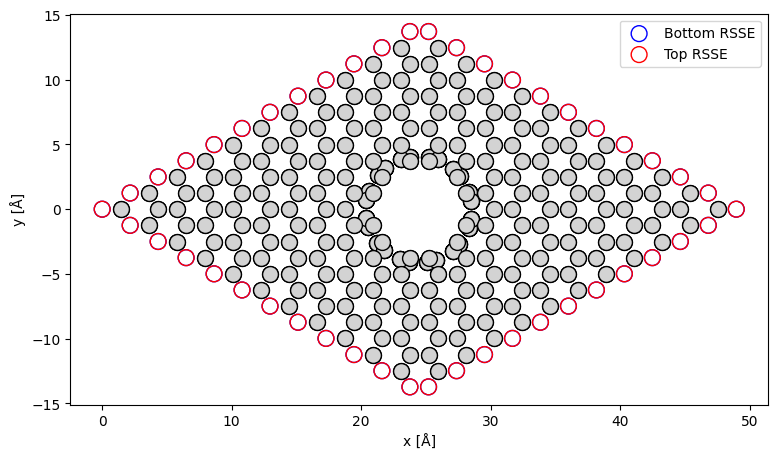

In [283]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.set_aspect("equal")
ax.scatter( gr_cnt_gr.xyz[rs_bottom_global,0], gr_cnt_gr.xyz[rs_bottom_global, 1], facecolors="none", edgecolors="blue", s=130, label="Bottom RSSE",zorder=2)
ax.scatter(  gr_cnt_gr.xyz[rs_top_global, 0],  gr_cnt_gr.xyz[rs_top_global,1],  facecolors="none",   edgecolors="red",  s=130,   label="Top RSSE",zorder=2)
ax.scatter(  gr_cnt_gr.xyz[idx_dev,0],  gr_cnt_gr.xyz[idx_dev, 1],  c="lightgray",  edgecolors="k",  zorder=0,  s=130)
ax.legend()
ax.set_xlabel("x [Å]")
ax.set_ylabel("y [Å]")
plt.show()

In [284]:
dos_total  = np.zeros(len(En))
dos_bottom = np.zeros(len(En))
dos_cnt    = np.zeros(len(En))
dos_top    = np.zeros(len(En))
ldos       = np.zeros((len(En),n_dev))  

In [285]:
transmission = np.zeros(len(En))
for iE, E in enumerate(tqdm(En, unit="E")):
    z = E + 1j * eta

    # RSSE 
    RSE_b = RSSE_bottom.self_energy(E,coupling=True) 
    RSE_t =  RSSE_top.self_energy(E,coupling=True)

    A = z * Sk - Hk
    SE_B=np.zeros(A.shape,dtype=complex)
    SE_T=np.zeros(A.shape,dtype=complex)
    
    SE_B[np.ix_(rs_bottom_global, rs_bottom_global)] -= RSE_b
    SE_T[np.ix_(rs_top_global,rs_top_global) ] -= RSE_t

    A+= (SE_B+SE_T)

    # Greens function 
    G = np.linalg.inv(A)

    # SE_B/SE_T store -Sigma; Gamma must use the opposite sign.
    Gamma_B = -1j * (SE_B - SE_B.conj().T)
    Gamma_T = -1j * (SE_T - SE_T.conj().T)

    # Transmission
    transmission[iE] = np.real(np.trace( Gamma_B @ G @ Gamma_T@ G.conj().T))
    GS = G @ Sk

    dos_atom = -np.imag( np.diag(GS) ) / np.pi
    dos_total[iE] = dos_atom.sum()
    dos_bottom[iE] = dos_atom[ :n_bottom ].sum()
    dos_cnt[iE] = dos_atom[ n_bottom:n_bottom+n_cnt].sum()
    dos_top[iE] = dos_atom[ n_bottom+n_cnt: ].sum()
    ldos[iE] = - (1.0 / np.pi) * np.imag(np.diag(GS))

  0%|          | 0/61 [00:00<?, ?E/s]

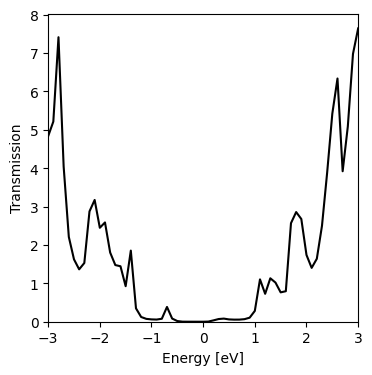

In [287]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(En,transmission,c='k')
ax.set_xlabel("Energy [eV]")
ax.set_ylabel("Transmission")
plt.xlim(-3,3)
plt.ylim(0,None)
plt.show()

## 4. Visualize the DOS and LDOS

The DOS projections show which part of the device contributes states at a given energy. The LDOS maps provide the complementary real-space picture: they show where those states are localized within the graphene–CNT–graphene structure.


In [290]:
# Find the closest energy
E0 =1.75 # Energy of interest
E_idx = np.argmin(np.abs(En - E0))

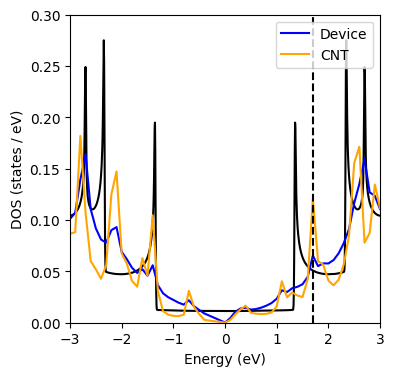

In [291]:
plt.figure(figsize=(4,4))
plt.plot(Energies,DOS_CNT,c='k' )
plt.plot(En,dos_total/n_dev,'-b',label='Device')
plt.plot(En,dos_cnt/n_cnt,c='orange',label='CNT')
plt.vlines(x=En[E_idx],ymin=0,ymax=0.35,color='k',linestyle='dashed')
plt.xlabel("Energy (eV)")
plt.ylabel("DOS (states / eV)")
plt.xlim(-3,3)
plt.ylim(0,0.3)
plt.legend(loc=1)
plt.show()

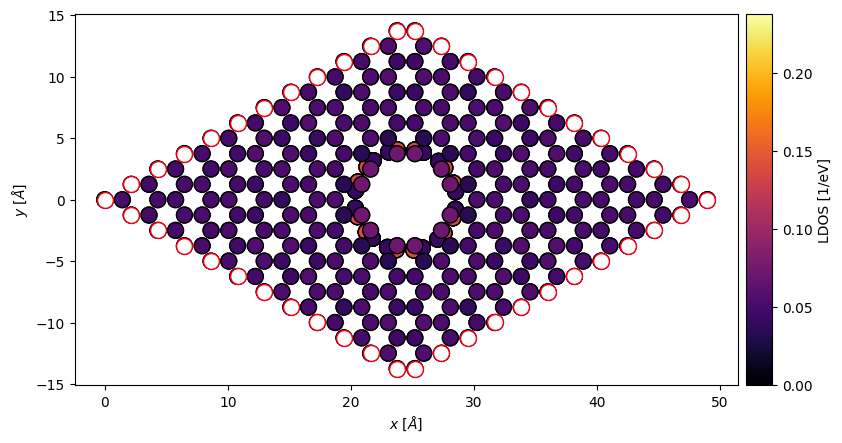

In [292]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.set_aspect("equal")

sc=ax.scatter(gr_cnt_gr.xyz[:, 0], gr_cnt_gr.xyz[:, 1],  c=ldos[E_idx], s=130,edgecolors='k',cmap='inferno',vmin=0)
ax.scatter(gr_cnt_gr.xyz[rs_bottom_global, 0],gr_cnt_gr.xyz[rs_bottom_global, 1],edgecolors="blue",c='white', s=130,label="Bottom RSSE")
ax.scatter( gr_cnt_gr.xyz[rs_top_global, 0], gr_cnt_gr.xyz[rs_top_global, 1],edgecolors="red",c='white', s=130, label="Top RSSE")

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%",  pad=0.08)
cbar = fig.colorbar( sc,   cax=cax)
cbar.set_label("LDOS [1/eV]")
ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$y$ [$\AA$]")
plt.show()

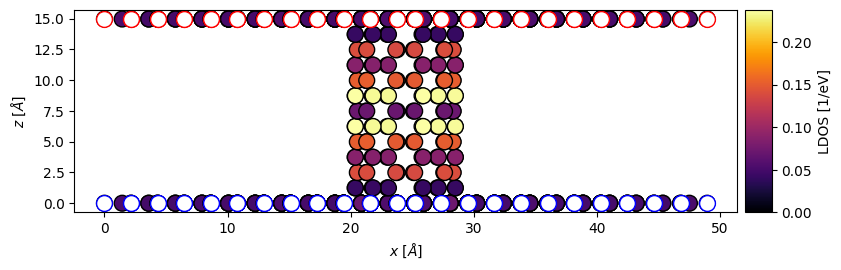

In [293]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.set_aspect("equal")

sc=ax.scatter(gr_cnt_gr.xyz[:, 0], gr_cnt_gr.xyz[:, 2],  c=ldos[E_idx], s=130,edgecolors='k',cmap='inferno',vmin=0)
ax.scatter(gr_cnt_gr.xyz[rs_bottom_global, 0],gr_cnt_gr.xyz[rs_bottom_global, 2],edgecolors="blue",c='white', s=130,label="Bottom RSSE")
ax.scatter( gr_cnt_gr.xyz[rs_top_global, 0], gr_cnt_gr.xyz[rs_top_global,2],edgecolors="red",c='white', s=130, label="Top RSSE")

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%",  pad=0.08)
cbar = fig.colorbar( sc,   cax=cax)
cbar.set_label("LDOS [1/eV]")
ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$z$ [$\AA$]")
plt.show()

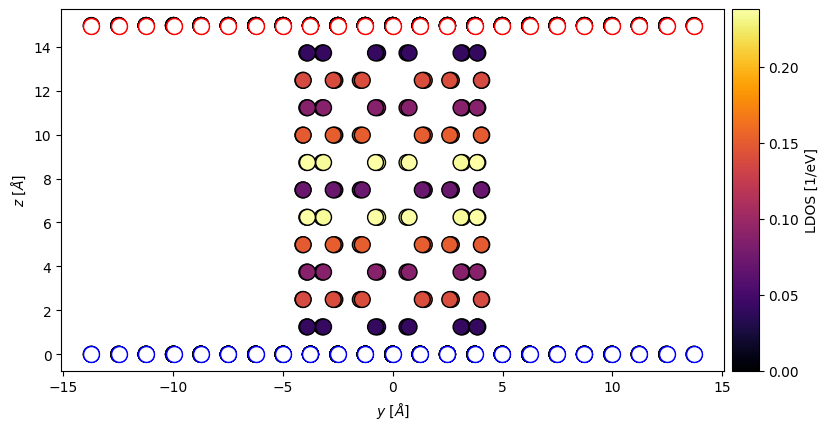

In [294]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.set_aspect("equal")

sc=ax.scatter(gr_cnt_gr.xyz[:,1], gr_cnt_gr.xyz[:,2],  c=ldos[E_idx], s=130,edgecolors='k',cmap='inferno',vmin=0)
ax.scatter(gr_cnt_gr.xyz[rs_bottom_global,1],gr_cnt_gr.xyz[rs_bottom_global, 2],edgecolors="blue",c='white', s=130,label="Bottom RSSE")
ax.scatter( gr_cnt_gr.xyz[rs_top_global,1], gr_cnt_gr.xyz[rs_top_global,2],edgecolors="red",c='white', s=130, label="Top RSSE")

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%",  pad=0.08)
cbar = fig.colorbar( sc,   cax=cax)
cbar.set_label("LDOS [1/eV]")
ax.set_xlabel(r"$y$ [$\AA$]")
ax.set_ylabel(r"$z$ [$\AA$]")
plt.show()

### CNT bond currents: source-resolved flow from bottom graphene

For the two graphene electrodes, we inject from the **bottom** one:

$$\mathbf A_B(E_0)=\mathbf G^r(E_0)\boldsymbol\Gamma_B(E_0)\mathbf G^a(E_0),$$

$$j_{i\to j}^{(B)}(E_0)=-2\,\mathrm{Im}\!\left[\big(H_{ij}-E_0S_{ij}\big)(A_B)_{ji}\right].$$

The arrows show where states incoming from bottom graphene propagate through the CNT and into the top electrode. Negative values reverse arrow directions. In a two-terminal device, the **signed sum** of these bond currents across a complete bottom-to-top cut should approach the transmission $T(E_0)$ (per spin). This is a useful check of indexing, signs, and Hamiltonian connectivity. Finite $\eta$ acts as additional weak absorption, so exact current conservation requires the $\eta\to0^+$ limit and consistent electrode broadenings. The plotted $j^{(B)}$ is not an equilibrium net current.

In [295]:
E0 =1.75 # Energy of interest

In [296]:
Hk = H_dev.Hk(format="array")
Sk = H_dev.Sk(format="array")

z = E0 + 1j * eta
# RSSE
RSE_b = RSSE_bottom.self_energy(E0, coupling=True)
RSE_t = RSSE_top.self_energy(E0, coupling=True)

A = z * Sk - Hk
SE_B = np.zeros(A.shape, dtype=complex)
SE_T = np.zeros(A.shape, dtype=complex)
SE_B[np.ix_(rs_bottom_global, rs_bottom_global)] = RSE_b
SE_T[np.ix_(rs_top_global, rs_top_global)] = RSE_t

# Here SE_B/SE_T store +Sigma; subtract them from z*S-H.
A -= (SE_B + SE_T)
G = np.linalg.inv(A)

# Physical broadenings
Gamma_B = 1j * (SE_B - SE_B.conj().T)
Gamma_T = 1j * (SE_T - SE_T.conj().T)

# Injection from bottom graphene
A_B = G @ Gamma_B @ G.conj().T

In [297]:
xyz = H_dev.geometry.xyz

# Candidate nearest-neighbor bonds; discard pairs with no hopping.
tree = cKDTree(xyz)
bonds = np.array(sorted(tree.query_pairs(r=1.7)), dtype=int).reshape(-1, 2)
atom_i, atom_j = bonds[:, 0], bonds[:, 1]
coupled = np.abs(Hk[atom_i, atom_j] - E0 * Sk[atom_i, atom_j]) > 1e-12
atom_i, atom_j = atom_i[coupled], atom_j[coupled]

# Spectral particle current i -> j, injected from bottom graphene.
Jij = -2 * np.imag(
    (Hk[atom_i, atom_j] - E0 * Sk[atom_i, atom_j]) * A_B[atom_j, atom_i]
)

# Signed bottom-graphene -> rest-of-device flux versus T(E0).
cut = (atom_i < n_bottom) & (atom_j >= n_bottom)
J_cut = Jij[cut].sum()
T_E0 = np.real(np.trace(Gamma_B @ G @ Gamma_T @ G.conj().T))
print(f"Bottom-graphene cut flux: {J_cut:.5g}; T(E0): {T_E0:.5g}")

threshold = 1e-5 * np.max(np.abs(Jij))
mask = np.abs(Jij) > threshold

i, j, J = atom_i[mask], atom_j[mask], Jij[mask]

# Reverse arrows where the signed current is negative.
start = np.where(J[:, None] >= 0, xyz[i], xyz[j])
end = np.where(J[:, None] >= 0, xyz[j], xyz[i])
dx = end[:, 0] - start[:, 0]
dy = end[:, 1] - start[:, 1]
dz = end[:, 2] - start[:, 2]

Bottom-graphene cut flux: 2.6971; T(E0): 2.6255


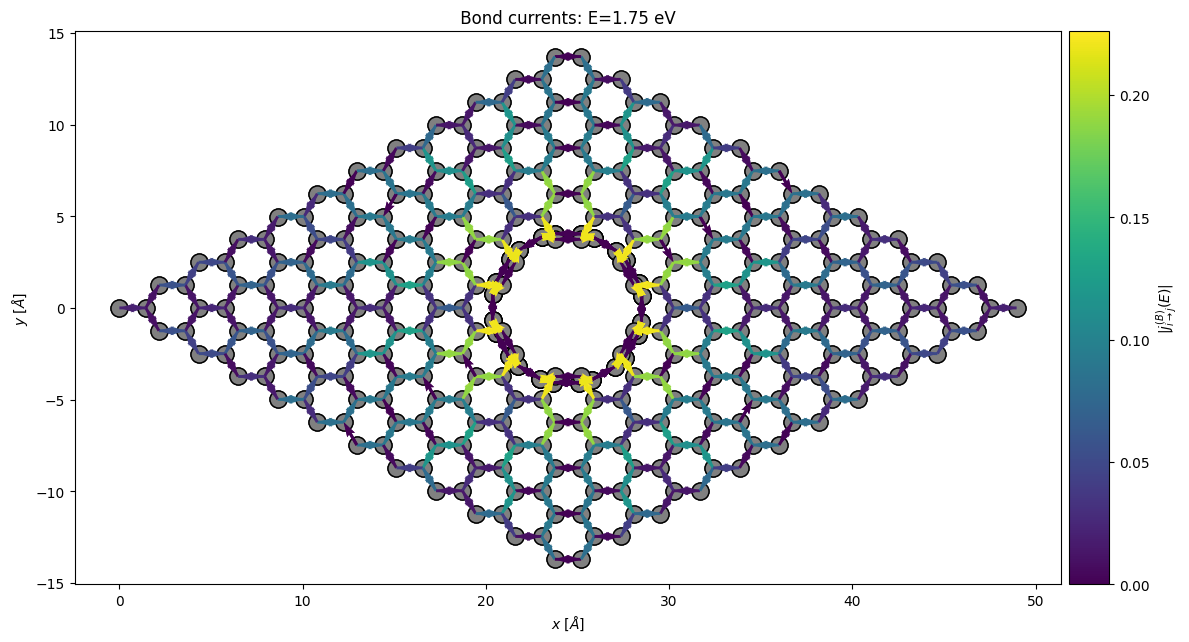

In [298]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_aspect("equal")

# Device atoms (carbon)
ax.scatter(xyz[:, 0], xyz[:,1],s=150, c="gray",zorder=0,edgecolors='k')

# Bond-current arrows
q = ax.quiver(
    start[:, 0],
    start[:, 1],
    dx,
    dy,
    np.abs(J),
    cmap="viridis",
    norm=Normalize(
        vmin=0,
        vmax=np.max(np.abs(Jij))
    ),
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.003,
    headwidth=3,
    zorder=2
)


divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.08)
cbar = fig.colorbar(q, cax=cax)
cbar.set_label(label=r"$|j_{i\to j}^{(B)}(E)|$")

ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$y$ [$\AA$]")

ax.set_title( rf" Bond currents: E={E0:.2f} eV ")

plt.tight_layout()
plt.show()


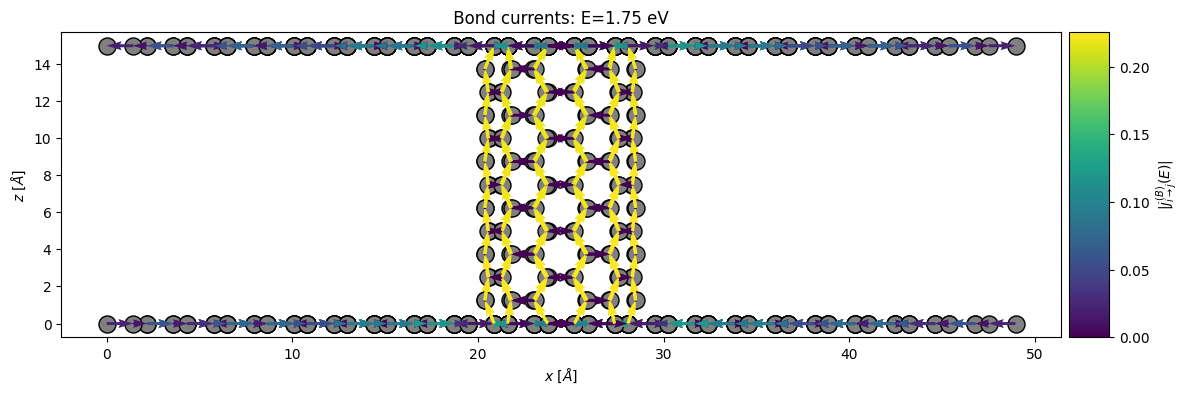

In [299]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_aspect("equal")

# Device atoms (carbon)
ax.scatter(xyz[:, 0], xyz[:,2],s=150, c="gray",zorder=0,edgecolors='k')

# Bond-current arrows
q = ax.quiver(
    start[:, 0],
    start[:, 2],
    dx,
    dz,
    np.abs(J),
    cmap="viridis",
    norm=Normalize(
        vmin=0,
        vmax=np.max(np.abs(Jij))
    ),
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.003,
    headwidth=3,
    zorder=2
)


divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.08)
cbar = fig.colorbar(q, cax=cax)
cbar.set_label(label=r"$|j_{i\to j}^{(B)}(E)|$")

ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$z$ [$\AA$]")

ax.set_title( rf" Bond currents: E={E0:.2f} eV ")

plt.tight_layout()
plt.show()


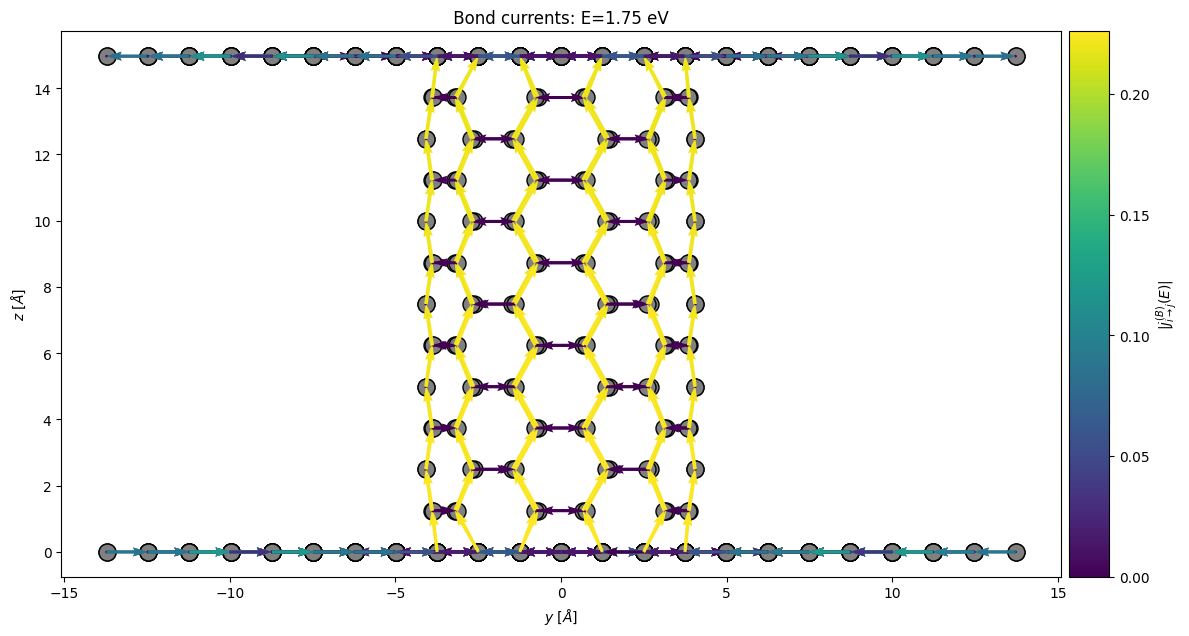

In [300]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_aspect("equal")

# Device atoms (carbon)
ax.scatter(xyz[:, 1], xyz[:,2],s=150, c="gray",zorder=0,edgecolors='k')

# Bond-current arrows
q = ax.quiver(
    start[:, 1],
    start[:, 2],
    dy,
    dz,
    np.abs(J),
    cmap="viridis",
    norm=Normalize(
        vmin=0,
        vmax=np.max(np.abs(Jij))
    ),
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.003,
    headwidth=3,
    zorder=2
)


divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.08)
cbar = fig.colorbar(q, cax=cax)
cbar.set_label(label=r"$|j_{i\to j}^{(B)}(E)|$")


ax.set_xlabel(r"$y$ [$\AA$]")
ax.set_ylabel(r"$z$ [$\AA$]")

ax.set_title( rf" Bond currents: E={E0:.2f} eV ")

plt.tight_layout()
plt.show()
